In [1]:
from imports import *

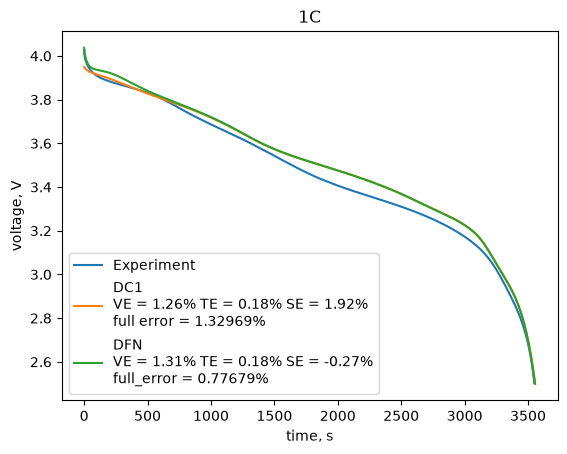

In [2]:
t_eval = np.linspace(0, 4000, 4001)

data = np.loadtxt("data1C.data")

params = PARAMS.paramsDC1()
params["I"] = lambda t: np.mean(data[:,2]) / 0.1027
dc1 = DC1()
dc1.init(params, 30)
solDC1 = dc1.run({}, t_eval)
errDC1 = ERRORS.calc_errors(np.column_stack([data[:,0], data[:,1]]), np.column_stack([solDC1.t, solDC1["voltage"].entries]), 1, 1, 1)

params = PARAMS.paramsDFN()
params["I"] = lambda t: np.mean(data[:,2]) / 0.1027
dfn = DFN()
dfn.init(params, 30, 30)
solDFN = dfn.run({}, t_eval)
errDFN = ERRORS.calc_errors(np.column_stack([data[:,0], data[:,1]]), np.column_stack([solDFN.t, solDFN["voltage"].entries]), 1, 1, 1)


plt.plot(data[:,0], data[:,1], label="Experiment")
plt.plot(solDC1.t, solDC1["voltage"].entries,
    label="DC1\n"
    f"VE = {errDC1[0] * 100:.2f}% TE = {errDC1[1] * 100:.2f}% SE = {errDC1[2] * 100:.2f}%\n"
    f"full error = {np.sqrt(np.mean(errDC1 ** 2)) * 100:.5f}%"
)
plt.plot(solDFN.t, solDFN["voltage"].entries,
    label="DFN\n"
    f"VE = {errDFN[0] * 100:.2f}% TE = {errDFN[1] * 100:.2f}% SE = {errDFN[2] * 100:.2f}%\n"
    f"full_error = {np.sqrt(np.mean(errDFN ** 2)) * 100:.5f}%"
)
plt.xlabel("time, s")
plt.ylabel("voltage, V")
plt.title("1C")
plt.legend()